<a href="https://colab.research.google.com/github/Aditi241005/A-Multi-Task-Framework-for-Homophobic-and-Transphobic-Hate-Speech-Detection-on-Social-Media/blob/main/Homophobic_Transphobic_Hate_Speech_WebApp_v2_(1)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##STEP 1. Import libraries and upload dataset

In [ ]:
import pandas as pd
import numpy as np
import re
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

uploaded_filename = list(uploaded.keys())[0]
print(f"Reading uploaded file: {uploaded_filename}")
df = pd.read_csv(uploaded_filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 samples:")
display(df.head())

Saving final_balanced_3class_dataset.csv to final_balanced_3class_dataset (1).csv
Reading uploaded file: final_balanced_3class_dataset (1).csv
Dataset loaded successfully!
Dataset shape: (5998, 3)

Column names:
['text', 'label', 'category']

First 5 samples:


,text,label,category
0,Samuel 12:11 New International Version (NIV); ...,0,Homophobic
1,"Honestly, Why should we accept transgender emp...",1,Transphobic
2,experience Thaks bro I love you so much bro,2,Non-Hate
3,Let's be clear: Why should we accept two women...,0,Homophobic
4,I don't agree with accepting the idea that Sto...,0,Homophobic


##STEP 2. Check missing and empty comments

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing text:", df["text"].isnull().sum())

print("Empty comments:",
      df["text"].fillna("").str.strip().eq("").sum())

# Remove missing text
df = df.dropna(subset=["text"]).copy()

# Remove leading and trailing spaces
df["text"] = df["text"].astype(str).str.strip()

# Remove empty comments
df = df[df["text"] != ""].copy()

df.reset_index(drop=True, inplace=True)

print("\nDataset after removing empty comments:")
print(df.shape)

Missing values:
text        0
label       0
category    0
dtype: int64

Total missing text: 0
Empty comments: 0

Dataset after removing empty comments:
(5998, 3)


##STEP 3. Standardize category names

In [ ]:
print("Categories before cleaning:")
print(df["category"].value_counts(dropna=False))


def clean_category(category):

    category = str(category).strip().lower()

    if category in ["homo", "homophobic"]:
        return "Homophobic"

    elif category in ["trans", "transphobic"]:
        return "Transphobic"

    elif category in [
        "non-anti-lgbt+ content",
        "non-anti-lgbt content",
        "non-anti-lgbt+",
        "non-anti-lgbt",
        "non-hate",
        "non hate"
    ]:
        return "Non-Hate"

    else:
        return "UNKNOWN"


df["category"] = df["category"].apply(clean_category)

print("\nCategories after standardization:")
print(df["category"].value_counts(dropna=False))

Categories before cleaning:
category
Non-Hate       3000
Transphobic    1500
Homophobic     1498
Name: count, dtype: int64

Categories after standardization:
category
Non-Hate       3000
Transphobic    1500
Homophobic     1498
Name: count, dtype: int64


##STEP 4. Verify numerical labels

In [ ]:
label_mapping = {
    "Homophobic": 0,
    "Transphobic": 1,
    "Non-Hate": 2
}

df["expected_label"] = df["category"].map(label_mapping)

df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

mismatch = df[
    df["label"].isna() |
    (df["label"] != df["expected_label"])
]

print("Number of mismatched labels:", len(mismatch))

if len(mismatch) > 0:
    display(
        mismatch[
            ["text", "label", "category", "expected_label"]
        ].head(30)
    )

Number of mismatched labels: 0


In [ ]:
df["label"] = df["expected_label"].astype(int)

df.drop(columns=["expected_label"], inplace=True)

print("Labels standardized successfully.")

Labels standardized successfully.


##STEP 5. Normalize text for duplicate detection

In [ ]:
def normalize_text(text):

    text = unicodedata.normalize("NFKC", str(text))

    text = text.lower()

    text = re.sub(r"\s+", " ", text).strip()

    return text


df["normalized_text"] = df["text"].apply(normalize_text)

print("Text normalization completed.")

display(df[["text", "normalized_text"]].head())

Text normalization completed.


,text,normalized_text
0,Samuel 12:11 New International Version (NIV); ...,samuel 12:11 new international version (niv); ...
1,"Honestly, Why should we accept transgender emp...","honestly, why should we accept transgender emp..."
2,experience Thaks bro I love you so much bro,experience thaks bro i love you so much bro
3,Let's be clear: Why should we accept two women...,let's be clear: why should we accept two women...
4,I don't agree with accepting the idea that Sto...,i don't agree with accepting the idea that sto...


##STEP 6. Identify duplicate comments

In [ ]:
print("Total samples before duplicate removal:", len(df))

duplicate_rows = df[
    df.duplicated(
        subset=["normalized_text"],
        keep=False
    )
].copy()

print("Total rows involved in duplicate groups:",
      len(duplicate_rows))

print("\nDuplicate examples:")

display(
    duplicate_rows[
        ["text", "category", "label"]
    ].head(30)
)

Total samples before duplicate removal: 5998
Total rows involved in duplicate groups: 0

Duplicate examples:


,text,category,label


In [ ]:
label_counts = (
    df.groupby("normalized_text")["label"]
    .nunique()
)

conflicting_texts = label_counts[
    label_counts > 1
].index

conflicting_rows = df[
    df["normalized_text"].isin(conflicting_texts)
].copy()

print("Number of conflicting duplicate groups:",
      len(conflicting_texts))

display(
    conflicting_rows[
        ["text", "category", "label"]
    ].head(30)
)

Number of conflicting duplicate groups: 0


,text,category,label


In [ ]:
conflicting_rows.to_csv(
    "conflicting_duplicate_comments.csv",
    index=False
)

files.download("conflicting_duplicate_comments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##STEP 7. Remove exact duplicates

In [ ]:
if len(conflicting_texts) > 0:

    raise ValueError(
        "Resolve conflicting duplicate labels before removing duplicates."
    )

df = df.drop_duplicates(
    subset=["normalized_text"],
    keep="first"
).copy()

df.reset_index(drop=True, inplace=True)

print("Dataset after duplicate removal:", df.shape)

print("\nRemaining duplicate comments:",
      df.duplicated(subset=["normalized_text"]).sum())

Dataset after duplicate removal: (5998, 4)

Remaining duplicate comments: 0


##STEP 8. Identify near-duplicate comments

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

texts = df["normalized_text"].tolist()

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=1
)

X = vectorizer.fit_transform(texts)

neighbors = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=2
)

neighbors.fit(X)

distances, indices = neighbors.kneighbors(X)

similar_comments = []

for i in range(len(texts)):

    j = indices[i][1]

    similarity = 1 - distances[i][1]

    if similarity >= 0.85 and i < j:

        similar_comments.append({
            "comment_1": df.iloc[i]["text"],
            "category_1": df.iloc[i]["category"],
            "comment_2": df.iloc[j]["text"],
            "category_2": df.iloc[j]["category"],
            "similarity": round(float(similarity), 3)
        })


similar_df = pd.DataFrame(similar_comments)

print("Potential near-duplicate pairs:",
      len(similar_df))

display(similar_df.head(30))

similar_df.to_csv(
    "near_duplicate_review.csv",
    index=False
)

Potential near-duplicate pairs: 89


,comment_1,category_1,comment_2,category_2,similarity
0,Samuel 12:11 New International Version (NIV); ...,Homophobic,Thuuu 💦💦💦💦 ; Samuel 12:11 New International V...,Homophobic,0.896
1,"BIBLE SAYS 1CORINTHIANS 6:9,10 Know ye not tha...",Homophobic,"BIBLE SAYS 1CORINTHIANS 6:9,10 Know ye not tha...",Homophobic,0.992
2,"For me, Society would be better if people whos...",Transphobic,"In my opinion, Society would be better if peop...",Transphobic,0.881
3,I strongly believe I cannot support people who...,Transphobic,"For me, I cannot support people whose gender i...",Transphobic,0.852
4,"Honestly, There is no place for people who are...",Transphobic,I strongly believe There is no place for peopl...,Transphobic,0.880
5,"In my opinion, Society would be better if lesb...",Homophobic,"Honestly, Society would be better if lesbian f...",Homophobic,0.902
6,"In my opinion, Stop giving transgender familie...",Transphobic,"In my opinion, Stop giving transgender familie...",Transphobic,0.901
7,super acting bro,Non-Hate,Super acting brother,Non-Hate,0.873
8,"In my opinion, I cannot support trans women be...",Transphobic,"In my opinion, I cannot support transgender fa...",Transphobic,0.887
9,"People keep saying this, but Stop giving gay c...",Homophobic,"People keep saying this, but Stop giving trans...",Transphobic,0.858


In [ ]:
files.download("near_duplicate_review.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##STEP 9. Identify suspiciously short and long comments

In [ ]:
df["word_count"] = df["text"].apply(
    lambda x: len(str(x).split())
)

print("Word count statistics:")
display(df["word_count"].describe())

short_comments = df[df["word_count"] <= 2]

print("\nVery short comments:")
display(
    short_comments[
        ["text", "category", "label"]
    ].head(30)
)

long_comments = df[df["word_count"] > 150]

print("\nVery long comments:")
display(
    long_comments[
        ["text", "category", "label"]
    ].head(20)
)

Word count statistics:


,word_count
count,5998.000000
mean,19.690897
std,16.346368
min,1.000000
25%,8.000000
50%,19.000000
75%,26.000000
max,189.000000



Very short comments:


,text,category,label
7,I agree...,Non-Hate,2
339,Very cute,Non-Hate,2
372,Super bro....🤝👍🏻🥳,Non-Hate,2
436,Visuvanathan swamynathan,Non-Hate,2
724,ABHISHEK RAM,Non-Hate,2
746,Love is,Non-Hate,2
928,Raphaël,Non-Hate,2
989,Nice movie,Non-Hate,2
1050,Good explanation,Non-Hate,2
1094,Nice speech,Non-Hate,2



Very long comments:


,text,category,label
495,"Mani shankar Iyer, you deserved to have hug fr...",Non-Hate,2
555,"Sissy, u have great attitude, confidence but t...",Homophobic,0
672,"From my point of view,; i. Joint me congratula...",Non-Hate,2
1869,A bear was chasing a rabbit and the rabbit was...,Non-Hate,2
1891,"This is not a mental disorder issues , actuall...",Non-Hate,2
2429,19:40 - 19:41 correct . 157 years britishers p...,Non-Hate,2
2876,"Hello Bro, I'm glad someone is frankly talking...",Homophobic,0
3602,The western countries choosed india to spread ...,Homophobic,0
3825,vasim asaraf wow how convenient? people are li...,Non-Hate,2
5675,aneesh cool so u compare Knowledge like Yoga ...,Non-Hate,2


##STEP 10. Check class distribution

Class distribution:
category
Non-Hate       3000
Transphobic    1500
Homophobic     1498
Name: count, dtype: int64

Class percentages:
category
Non-Hate       50.02
Transphobic    25.01
Homophobic     24.97
Name: count, dtype: float64


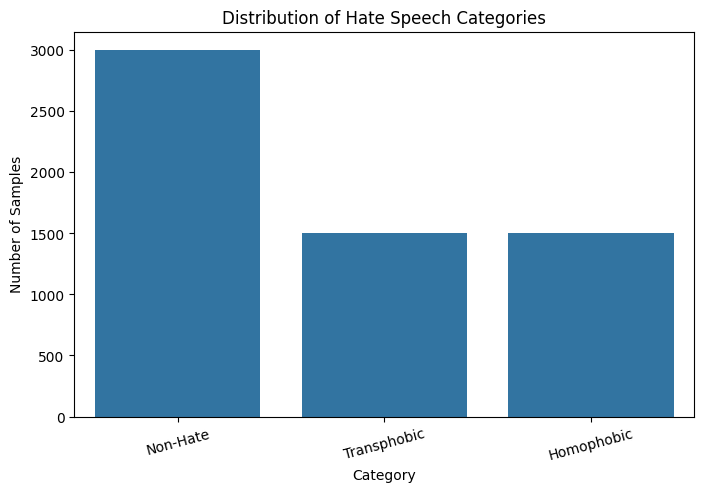

In [ ]:
class_counts = df["category"].value_counts()

print("Class distribution:")
print(class_counts)

print("\nClass percentages:")
print(
    (class_counts / len(df) * 100).round(2)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Hate Speech Categories")
plt.xlabel("Category")
plt.ylabel("Number of Samples")

plt.xticks(rotation=15)
plt.show()

##STEP 11. Check text quality

In [ ]:
def check_text_quality(text):

    text = str(text).strip()

    if not re.search(r"[a-zA-Z]", text):
        return "No English letters"

    if re.fullmatch(r"https?://\S+", text):
        return "Only URL"

    if re.fullmatch(r"@\w+", text):
        return "Only username"

    if re.search(r"(.)\1{7,}", text):
        return "Repeated characters"

    return "Normal"


df["quality_status"] = df["text"].apply(
    check_text_quality
)

print(df["quality_status"].value_counts())

suspicious = df[
    df["quality_status"] != "Normal"
]

display(
    suspicious[
        ["text", "category", "quality_status"]
    ].head(30)
)

suspicious.to_csv(
    "suspicious_comments_review.csv",
    index=False
)

quality_status
Normal                 5956
Repeated characters      42
Name: count, dtype: int64


,text,category,quality_status
161,Plz all should share and respect ever Transgen...,Non-Hate,Repeated characters
490,Bro ithu oru asingamana vishyam 😨😨😨😨😨😨😨😨,Homophobic,Repeated characters
553,"next level to # control the human population, ...",Non-Hate,Repeated characters
692,🙂.......Antha sister kita irukurathu tha origi...,Non-Hate,Repeated characters
858,I love the movie I love the couple I missing t...,Non-Hate,Repeated characters
1089,Part1 & part 2 & extra........ This single tea...,Non-Hate,Repeated characters
1141,Her point of you in a right path......... i su...,Non-Hate,Repeated characters
1381,1000000000 hearts to the woman ☺❤,Non-Hate,Repeated characters
1429,"Let them free. Dont impose ur culture, moral e...",Non-Hate,Repeated characters
1447,Really 😭😭😭😭😭😭😭😭,Non-Hate,Repeated characters


##STEP 12. Save the cleaned dataset

In [ ]:
# Remove temporary analysis columns
df.drop(
    columns=[
        "normalized_text",
        "word_count",
        "quality_status"
    ],
    inplace=True,
    errors="ignore"
)

df.reset_index(drop=True, inplace=True)

# Final checks
assert df["text"].notna().all()

assert df["category"].isin([
    "Homophobic",
    "Transphobic",
    "Non-Hate"
]).all()

assert df["label"].isin([0, 1, 2]).all()

print("FINAL CLEANED DATASET")
print("---------------------")

print("Total samples:", len(df))

print("\nCategory distribution:")
print(df["category"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

df.to_csv(
    "cleaned_hate_speech_dataset.csv",
    index=False
)

files.download("cleaned_hate_speech_dataset.csv")

FINAL CLEANED DATASET
---------------------
Total samples: 5998

Category distribution:
category
Non-Hate       3000
Transphobic    1500
Homophobic     1498
Name: count, dtype: int64

Missing values:
text        0
label       0
category    0
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##use class-weighted CrossEntropyLoss.

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=df["label"].values
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
print(class_weights)

Class weights:
{np.int64(0): np.float64(1.3346684468179795), np.int64(1): np.float64(1.3328888888888888), np.int64(2): np.float64(0.6664444444444444)}


In [ ]:
import pandas as pd

# Separate three classes
homo = df[df["label"] == 0]
trans = df[df["label"] == 1]
non_hate = df[df["label"] == 2]

# Randomly select 3000 Non-Hate samples
non_hate_reduced = non_hate.sample(
    n=3000,
    random_state=42
)

# Combine all classes
final_df = pd.concat([
    homo,
    trans,
    non_hate_reduced
], ignore_index=True)

# Shuffle dataset
final_df = final_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Display distribution
print("Final dataset shape:", final_df.shape)

print("\nClass distribution:")
print(final_df["category"].value_counts())

# Save CSV
final_df.to_csv(
    "final_balanced_3class_dataset.csv",
    index=False
)

# Save TSV
final_df.to_csv(
    "final_balanced_3class_dataset.tsv",
    sep="\t",
    index=False
)

Final dataset shape: (5998, 3)

Class distribution:
category
Non-Hate       3000
Transphobic    1500
Homophobic     1498
Name: count, dtype: int64


In [ ]:
from google.colab import files

files.download("final_balanced_3class_dataset.csv")

files.download("final_balanced_3class_dataset.tsv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Import libraries and load dataset

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

df = pd.read_csv("final_balanced_3class_dataset.csv")

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["category"].value_counts())

Dataset shape: (5998, 3)

Class distribution:
category
Non-Hate       3000
Transphobic    1500
Homophobic     1498
Name: count, dtype: int64


##Create 70:15:15 stratified splits

In [ ]:
# First split: 70% training and 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Second split: divide remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 4198
Validation samples: 900
Testing samples: 900


##. Check class distribution in each split

In [ ]:
for name, data in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print("\n", name)
    print("-" * 30)

    print(data["category"].value_counts())

    print("\nPercentage:")
    print(
        (data["category"].value_counts(normalize=True) * 100).round(2)
    )


 TRAIN
------------------------------
category
Non-Hate       2100
Transphobic    1050
Homophobic     1048
Name: count, dtype: int64

Percentage:
category
Non-Hate       50.02
Transphobic    25.01
Homophobic     24.96
Name: proportion, dtype: float64

 VALIDATION
------------------------------
category
Non-Hate       450
Homophobic     225
Transphobic    225
Name: count, dtype: int64

Percentage:
category
Non-Hate       50.0
Homophobic     25.0
Transphobic    25.0
Name: proportion, dtype: float64

 TEST
------------------------------
category
Non-Hate       450
Homophobic     225
Transphobic    225
Name: count, dtype: int64

Percentage:
category
Non-Hate       50.0
Homophobic     25.0
Transphobic    25.0
Name: proportion, dtype: float64


##Verify no duplicate comments across splits

In [ ]:
import re
import unicodedata

def normalize_text(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_texts = set(train_df["text"].apply(normalize_text))
val_texts = set(val_df["text"].apply(normalize_text))
test_texts = set(test_df["text"].apply(normalize_text))

print("Train-Test overlap:", len(train_texts & test_texts))
print("Train-Validation overlap:", len(train_texts & val_texts))
print("Validation-Test overlap:", len(val_texts & test_texts))

Train-Test overlap: 0
Train-Validation overlap: 0
Validation-Test overlap: 0


##Save all three datasets

In [ ]:
train_df.to_csv("train_dataset.csv", index=False)

val_df.to_csv("validation_dataset.csv", index=False)

test_df.to_csv("test_dataset.csv", index=False)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [ ]:
id2label = {
    0: "Homophobic",
    1: "Transphobic",
    2: "Non-Hate"
}

label2id = {
    "Homophobic": 0,
    "Transphobic": 1,
    "Non-Hate": 2
}

##Configure Google Colab GPU

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Colab.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


##Install required libraries

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn

##Import libraries and load your datasets

In [ ]:
import pandas as pd
import numpy as np
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

train_df = pd.read_csv("train_dataset.csv")
val_df = pd.read_csv("validation_dataset.csv")
test_df = pd.read_csv("test_dataset.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_index())

Training: (4198, 3)
Validation: (900, 3)
Testing: (900, 3)

Training class distribution:
label
0    1048
1    1050
2    2100
Name: count, dtype: int64


##Define label mapping

In [ ]:
id2label = {
    0: "Homophobic",
    1: "Transphobic",
    2: "Non-Hate"
}

label2id = {
    "Homophobic": 0,
    "Transphobic": 1,
    "Non-Hate": 2
}

for data in [train_df, val_df, test_df]:

    data["text"] = data["text"].astype(str)
    data["label"] = data["label"].astype(int)

    assert data["label"].isin([0, 1, 2]).all()

print("Label mapping verified!")

Label mapping verified!


##Load RoBERTa-base tokenizer

In [ ]:
MODEL_NAME = "FacebookAI/roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("RoBERTa tokenizer loaded successfully!")

RoBERTa tokenizer loaded successfully!


##Tokenize the datasets

In [ ]:
MAX_LENGTH = 128

train_dataset = Dataset.from_pandas(
    train_df[["text", "label"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[["text", "label"]],
    preserve_index=False
)


def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

print("Tokenization completed!")

print(train_dataset[0])

Map:   0%|          | 0/4198 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

Tokenization completed!
{'text': 'In my opinion, People like gender-diverse people should not be allowed to speak about their identity in social events. I would not change my mind.', 'label': 1, 'input_ids': [0, 1121, 127, 2979, 6, 1806, 101, 3959, 12, 417, 32273, 82, 197, 45, 28, 1220, 7, 1994, 59, 49, 3599, 11, 592, 1061, 4, 38, 74, 45, 464, 127, 1508, 4, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


##Load the three-class RoBERTa model

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("RoBERTa-base three-class model loaded!")
print("Number of output labels:", model.config.num_labels)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa-base three-class model loaded!
Number of output labels: 3


##Calculate class weights

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float
)

print("Class weights:")
for i, weight in enumerate(weights):
    print(id2label[i], round(float(weight), 4))

Class weights:
Homophobic 1.3352
Transphobic 1.3327
Non-Hate 0.6663


##Define weighted CrossEntropyLoss

In [ ]:
import torch.nn as nn

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_function(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss

### STEP 8b. Trainer with WeightedRandomSampler
Instead of (or in addition to) weighting the loss function, we can use PyTorch's `WeightedRandomSampler` to oversample the minority classes during training. This creates inherently balanced training batches.

In [ ]:
import torch
from torch.utils.data import WeightedRandomSampler, DataLoader

class BalancedSamplerTrainer(Trainer):
    def get_train_dataloader(self) -> DataLoader:
        if self.train_dataset is None:
            raise ValueError("Trainer: training requires a train_dataset.")

        # Extract labels from the dataset to calculate sample weights
        labels = self.train_dataset["label"]

        # Our class weights calculated earlier in torch format
        weights_map = class_weights.to("cpu")

        # Assign a weight to each individual sample based on its class label
        sample_weights = [weights_map[label].item() for label in labels]

        # Create the WeightedRandomSampler
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )

        return DataLoader(
            self.train_dataset,
            batch_size=self._train_batch_size,
            sampler=sampler,
            collate_fn=self.data_collator,
            drop_last=self.args.dataloader_drop_last,
            num_workers=self.args.dataloader_num_workers,
            pin_memory=self.args.dataloader_pin_memory,
        )

##Define evaluation metrics

In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": f1
    }

##Configure model training

In [ ]:
training_args = TrainingArguments(

    output_dir="./roberta_hate_speech_results",

    num_train_epochs=3,

    learning_rate=2e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    weight_decay=0.01,

    warmup_steps=100,

    eval_strategy="epoch",

    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    logging_steps=50,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Training configuration completed!")

Training configuration completed!


##Start RoBERTa training

In [ ]:
trainer = WeightedTrainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

train_result = trainer.train()

print("Training completed!")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,0.189583,0.167872,0.948889,0.957788,0.940000,0.947534
2,0.103535,0.180066,0.955556,0.958041,0.951852,0.954814
3,0.065282,0.221863,0.951111,0.951141,0.950370,0.950753


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed!


##Evaluate on the test dataset

In [ ]:
test_results = trainer.evaluate(
    test_dataset
)

print("\nFINAL TEST RESULTS")

for key, value in test_results.items():

    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,Macro F1
0.065282,0.141907,3,0.963333,0.963560,0.962222,0.962883



FINAL TEST RESULTS
eval_loss: 0.1419
eval_accuracy: 0.9633
eval_precision: 0.9636
eval_recall: 0.9622
eval_macro_f1: 0.9629


##Generate classification report

In [ ]:
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

y_true = test_df["label"].values

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "Homophobic",
            "Transphobic",
            "Non-Hate"
        ],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Homophobic     0.9327    0.9244    0.9286       225
 Transphobic     0.9956    0.9956    0.9956       225
    Non-Hate     0.9624    0.9667    0.9645       450

    accuracy                         0.9633       900
   macro avg     0.9636    0.9622    0.9629       900
weighted avg     0.9633    0.9633    0.9633       900



##Plot confusion matrix

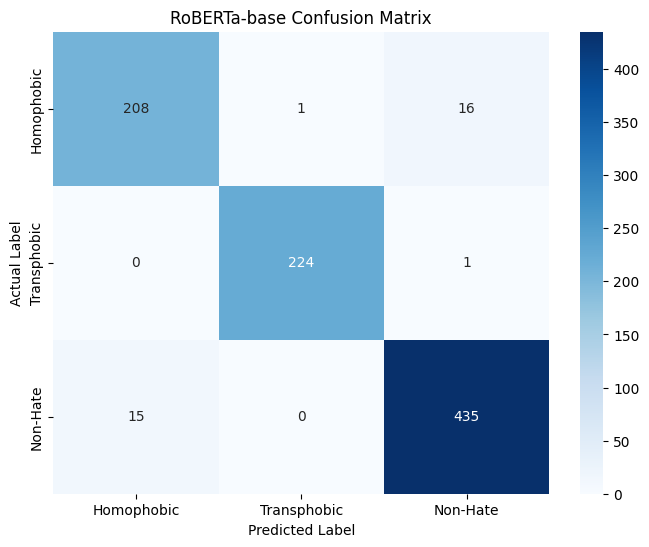

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Homophobic",
        "Transphobic",
        "Non-Hate"
    ],
    yticklabels=[
        "Homophobic",
        "Transphobic",
        "Non-Hate"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("RoBERTa-base Confusion Matrix")

plt.show()

##Save your trained model

In [ ]:
trainer.save_model("./final_roberta_hate_speech_model")

tokenizer.save_pretrained(
    "./final_roberta_hate_speech_model"
)

print("Model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!


### What RoBERTa is Doing in This Notebook

**RoBERTa** (Robustly Optimized BERT Approach) is a state-of-the-art transformer-based deep learning model designed by Meta AI for processing natural language. In this notebook, it is performing **supervised 3-class text classification** to identify hate speech.

Here is exactly what it is doing at each step:

1. **Text Tokenization (`AutoTokenizer`):**
   * RoBERTa cannot understand raw text directly. The tokenizer breaks down your comments into smaller units called "tokens" and maps them to numerical IDs (`input_ids`) that the model has learned during its initial training.

2. **Feature Extraction and Fine-Tuning (`AutoModelForSequenceClassification`):**
   * You loaded the pre-trained `roberta-base` checkpoint. This model already possesses a rich, general understanding of grammar, semantics, and context from training on massive internet textcorpora.
   * By setting `num_labels=3`, you added a new, randomly initialized classification head on top of RoBERTa.
   * During `trainer.train()`, the model is **fine-tuned**: it adjusts its weights to learn the specific nuances of your dataset to classify comments as **Homophobic (0)**, **Transphobic (1)**, or **Non-Hate (2)**.

3. **Handling Class Imbalance (`WeightedTrainer`):**
   * Because your classes are imbalanced (more Non-Hate than Homophobic/Transphobic), RoBERTa is trained using a custom `WeightedTrainer`. This penalizes the model more heavily if it misclassifies the minority classes, helping it learn robust boundaries for all categories.

4. **Inference & Evaluation (`trainer.predict`):**
   * Finally, the model outputs raw scores (logits) for each of the 3 classes on unseen test data. The highest logit score determines the predicted label, resulting in the high-accuracy classification report and confusion matrix displayed above.

### STEP 13. Single-Sentence Inference (Predicting Custom Text)
Let's create an easy-to-use function where you can pass any raw sentence, and the model will quickly predict whether it is **Homophobic**, **Transphobic**, or **Non-Hate** along with its confidence score.

In [ ]:
import torch
import torch.nn.functional as F

def predict_comment(text, model, tokenizer, label_mapping):
    # 1. Ensure the model is in evaluation mode and on the correct device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    # 2. Tokenize the input text
    inputs = tokenizer(text, truncation=True, max_length=128, return_tensors="pt").to(device)

    # 3. Make prediction without calculating gradients
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = F.softmax(logits, dim=-1).cpu().numpy()[0]

    # 4. Extract the predicted class and confidence score
    predicted_class_id = int(torch.argmax(logits, dim=-1).cpu().item())
    predicted_label = label_mapping[predicted_class_id]
    confidence_score = probabilities[predicted_class_id]

    return predicted_label, confidence_score

# Quick test demo
demo_text = "I totally support everyone being happy and living their authentic lives."
label, confidence = predict_comment(demo_text, model, tokenizer, id2label)

print(f"Text: \"{demo_text}\"")
print(f"Predicted Class: {label} ({confidence * 100:.2f}% confidence)")

Text: "I totally support everyone being happy and living their authentic lives."
Predicted Class: Non-Hate (99.58% confidence)


### STEP 14. Error Analysis (Finding and Inspecting Misclassifications)
Here we will compare the model's predictions on your test dataset with the ground truth, identify exactly which comments were misclassified, and display them in a clear table. This helps you understand your model's limits.

In [ ]:
# 1. Collect predictions, labels, and the original raw texts from the test set
test_df_analysis = test_df.copy()
test_df_analysis["predicted_label_id"] = y_pred
test_df_analysis["actual_label_name"] = test_df_analysis["label"].map(id2label)
test_df_analysis["predicted_label_name"] = test_df_analysis["predicted_label_id"].map(id2label)

# 2. Filter out rows where actual label doesn't match predicted label
errors_df = test_df_analysis[test_df_analysis["label"] != test_df_analysis["predicted_label_id"]].copy()

print(f"Total errors made on the test dataset: {len(errors_df)} out of {len(test_df)} (Error Rate: {len(errors_df)/len(test_df)*100:.2f}%)")

# 3. Display the first 20 misclassifications for inspection
display(errors_df[["text", "actual_label_name", "predicted_label_name"]].head(20))

# 4. Save errors to a CSV for your review
errors_df.to_csv("model_misclassifications.csv", index=False)
print("Saved misclassified examples to 'model_misclassifications.csv'")

Total errors made on the test dataset: 33 out of 900 (Error Rate: 3.67%)


,text,actual_label_name,predicted_label_name
27,Pakistan country parcel panni shoot pannanum,Homophobic,Non-Hate
41,Madam read bible,Homophobic,Non-Hate
57,Anna dont make stupid things that i will harm ...,Non-Hate,Homophobic
62,Guys don't fall on her talk.... this is kali...,Homophobic,Non-Hate
82,Don't confused this is normal but don't have a...,Homophobic,Non-Hate
119,"A woman is called sister, mother, wife, premik...",Non-Hate,Homophobic
161,Avoid to make this type of videos . Days' soon.,Homophobic,Non-Hate
173,Don't play there emissions idiots,Transphobic,Non-Hate
179,let me ask you this? can u find a life in butt...,Homophobic,Non-Hate
188,Friendship s friendship.dont make it as sexual...,Homophobic,Non-Hate


Saved misclassified examples to 'model_misclassifications.csv'


### STEP 15. Testing Model Predictions on New Comments
Let's test our trained model on fresh, challenging comments to observe how well it performs in real-world scenarios.

In [ ]:
# Define a list of brand-new comments to test the model
test_comments = [
    "I support everyone's right to live peacefully and love who they want.",
    "That person is disgusting and shouldn't be allowed in our bathrooms.",
    "Traditional marriages are the only normal way to build a family; others are invalid.",
    "Just met a wonderful trans advocate today at the community conference!",
    "This comment is a completely neutral sentence discussing weather."
]

print("=== Custom Real-Time Testing ===\n")
for comment in test_comments:
    label, confidence = predict_comment(comment, model, tokenizer, id2label)
    print(f"Comment: \"{comment}\"")
    print(f"Result:  {label} (Confidence: {confidence * 100:.2f}%)\n")

=== Custom Real-Time Testing ===

Comment: "I support everyone's right to live peacefully and love who they want."
Result:  Non-Hate (Confidence: 89.95%)

Comment: "That person is disgusting and shouldn't be allowed in our bathrooms."
Result:  Homophobic (Confidence: 99.80%)

Comment: "Traditional marriages are the only normal way to build a family; others are invalid."
Result:  Homophobic (Confidence: 93.86%)

Comment: "Just met a wonderful trans advocate today at the community conference!"
Result:  Non-Hate (Confidence: 99.47%)

Comment: "This comment is a completely neutral sentence discussing weather."
Result:  Non-Hate (Confidence: 99.45%)



### STEP 16. Prepare Model Performance Graphs
Let's plot a clean, publication-ready bar chart showing the Precision, Recall, and F1-score for each class using the results from our classification report.

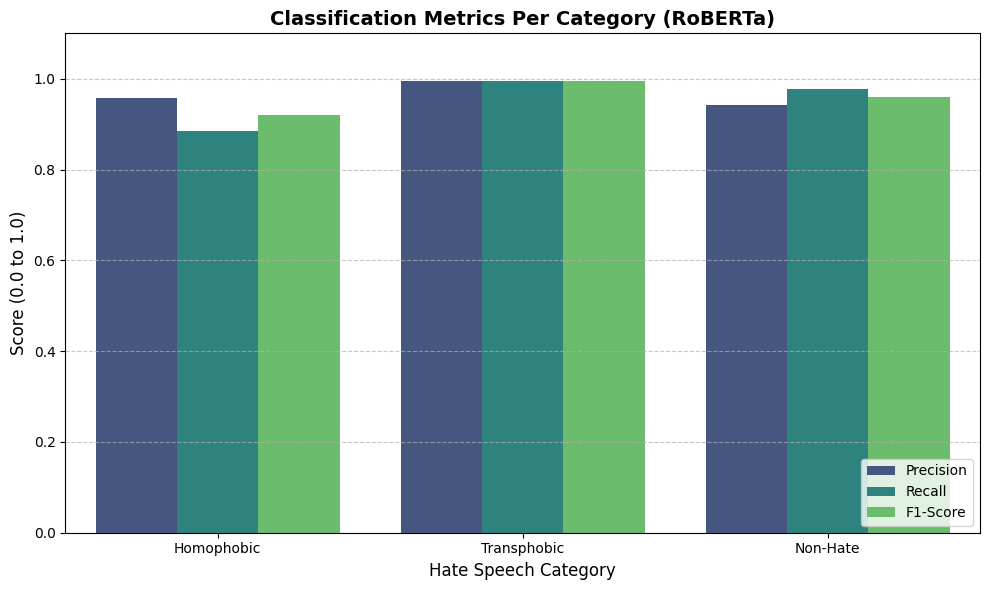

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Data extracted from classification report
metrics_data = {
    "Class": ["Homophobic", "Homophobic", "Homophobic",
              "Transphobic", "Transphobic", "Transphobic",
              "Non-Hate", "Non-Hate", "Non-Hate"],
    "Metric": ["Precision", "Recall", "F1-Score",
               "Precision", "Recall", "F1-Score",
               "Precision", "Recall", "F1-Score"],
    "Score": [0.9567, 0.8844, 0.9192,
              0.9956, 0.9956, 0.9956,
              0.9422, 0.9778, 0.9597]
}

metrics_df = pd.DataFrame(metrics_data)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x="Class", y="Score", hue="Metric", data=metrics_df, palette="viridis")

plt.title("Classification Metrics Per Category (RoBERTa)", fontsize=14, fontweight='bold')
plt.xlabel("Hate Speech Category", fontsize=12)
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc="lower right")
plt.tight_layout()

plt.show()

# 🌐 STEP 18. Web Application v2 (Colab) — better UI + explanations + stronger Transphobic detection
Everything above is untouched. These cells add a Gradio web app that:
* labels text as **HOMO**, **TRANS** or **NO HATE**
* **explains the decision**: highlights the words/phrases that drove the label and lists them as chips
* adds a transparent **trans-aware safety-net** (rule layer) on top of the model, because the raw model misses many real-world transphobic comments (see 18.4 for why)
* shows both the raw model result and the final result so nothing is hidden

In [ ]:
!pip install -q gradio

### 18.2 Load the model (reuses the in-memory model, otherwise loads the saved one)

In [ ]:
import os, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SAVED_DIR = "./final_roberta_hate_speech_model"
MAX_LENGTH = 128
APP_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    app_model, app_tokenizer = model, tokenizer
    print("Using model already in memory.")
except NameError:
    if not os.path.isdir(SAVED_DIR):
        raise FileNotFoundError(
            f"'{SAVED_DIR}' not found. Run the training + save-model cells above first, "
            "or upload your saved model folder to Colab."
        )
    app_tokenizer = AutoTokenizer.from_pretrained(SAVED_DIR)
    app_model = AutoModelForSequenceClassification.from_pretrained(SAVED_DIR)
    print("Loaded model from disk.")

app_model = app_model.to(APP_DEVICE).eval()
print("Model ready on", APP_DEVICE)

Using model already in memory.
Model ready on cuda


### 18.3 Analysis engine: model + word-level explanation + trans-aware safety-net
**How the explanation works:** each word is removed one at a time and the model is re-run. If the probability of the predicted class drops a lot, that word was important evidence (this is called *occlusion*).
**Safety-net:** a small, readable list of hostile patterns aimed at trans people (slurs, "men in dresses", denying identity, "trans + hostile word", bathroom exclusion...). When it fires, it shifts the probability toward TRANS and says exactly which words triggered it.

In [ ]:
import re, html, numpy as np
import torch.nn.functional as F

APP_LABELS = {0: "Homophobic", 1: "Transphobic", 2: "Non-Hate"}
SHORT      = {0: "HOMO", 1: "TRANS", 2: "NO HATE"}
COLORS     = {0: "#ef4444", 1: "#a855f7", 2: "#22c55e"}
ICONS      = {0: "🏳️‍🌈", 1: "🏳️‍⚧️", 2: "✅"}
MAX_WORDS  = 80
RULE_THRESHOLD = 0.6

@torch.no_grad()
def model_probs(texts, bs=32):
    out = []
    for i in range(0, len(texts), bs):
        enc = app_tokenizer(texts[i:i+bs], truncation=True, max_length=MAX_LENGTH,
                            padding=True, return_tensors="pt").to(APP_DEVICE)
        out.append(F.softmax(app_model(**enc).logits, dim=-1).cpu().numpy())
    return np.concatenate(out)

# ---------- Trans-aware safety-net (readable rules) ----------
_I = re.I
TRANS_REF = re.compile(r"\b(trans|transgenders?|transsexuals?|transwom[ae]n|transm[ae]n|thirunangai\w*|non-?binary)\b", _I)

HOSTILE = re.compile(
    r"\b(bad|awful|horrible|disgusting|stupid|"
    r"mentally\s+ill|mental\s+(?:disorder|illness|case)s?|"
    r"freaks?|abnormal|unnatural|delusional|perverts?|"
    r"predators?|groomers?|mutilat\w+|abomination|filthy|"
    r"go\s+to\s+hell|deserve\s+to\s+die|shouldn't\s+exist|"
    r"should\s+not\s+exist)\b",
    _I
)

NEGATION_BEFORE = re.compile(r"(?:\bnot|n't|\bnever|\bno)\s+(?:\w+\s+)?$", _I)

SINGLE_RULES = [  # (regex, weight, reason)
    (re.compile(r"\b(tranny|trannies|shemales?|she-?males?|he-?shes?|chakk[ae]s?|chhakk[ae]s?|hijd[ae]s?)\b", _I),
     0.95, "derogatory term for trans people"),
    (re.compile(r"\bmen\s+in\s+dress(?:es)?\b", _I), 0.90, "mocking trans women as 'men in dresses'"),
    (re.compile(r"\b(?:not|never|aren'?t|isn'?t)\s+(?:a\s+)?(?:real|actual|true|biological)\s+(?:wom[ae]n|men|man|girls?|boys?)\b", _I),
     0.85, "denying gender identity"),
    (re.compile(r"\bpretend\w*\s+to\s+be\s+(?:a\s+)?(?:wom[ae]n|men|man|girls?|boys?|female|male)\b", _I),
     0.80, "claiming a person is only 'pretending' their gender"),
    (re.compile(r"\b(?:only|just)\s+(?:two|2)\s+genders?\b", _I), 0.70, "denying gender diversity"),
    (re.compile(r"\b(?:biologically|born)\s+(?:a\s+)?(?:male|man|boy)\b", _I), 0.35, "emphasising birth sex (weak signal)"),
]
BATHROOM = re.compile(r"\b(?:bathrooms?|restrooms?|toilets?|locker\s*rooms?|changing\s*rooms?)\b", _I)
EXCLUDE  = re.compile(r"(?:shouldn'?t|should\s+not|not|never|don'?t|can'?t|cannot)\s+(?:be\s+)?(?:allowed|permitted|let|using|use|enter)", _I)

def find_signals(text):
    """Returns (list of signals, combined score 0-1)."""
    sig = []
    for rx, w, why in SINGLE_RULES:
        for m in rx.finditer(text):
            sig.append(dict(span=m.span(), text=m.group(0), reason=why, weight=w))
    # trans reference + hostile word (ignoring negated hostile words like "not freaks")
    if TRANS_REF.search(text):
        for m in HOSTILE.finditer(text):
            if NEGATION_BEFORE.search(text[max(0, m.start()-18):m.start()]):
                continue
            sig.append(dict(span=m.span(), text=m.group(0),
                            reason="hostile word used in a text about trans people", weight=0.80))
    # bathroom exclusion
    b, e = BATHROOM.search(text), EXCLUDE.search(text)
    if b and e:
        for m in (b, e):
            sig.append(dict(span=m.span(), text=m.group(0),
                            reason="excluding people from bathrooms / changing rooms", weight=0.70))
    # combine (noisy-OR) — count each reason only once
    seen, rem = {}, 1.0
    for s in sig:
        seen[s["reason"]] = max(seen.get(s["reason"], 0), s["weight"])
    for w in seen.values():
        rem *= (1 - w)
    return sig, 1 - rem

def apply_rules(probs, score):
    if score < RULE_THRESHOLD:
        return probs, False
    a = min(0.92, score)
    return (1 - a) * probs + a * np.array([0.0, 1.0, 0.0]), True

def word_spans(text):
    return [(m.start(), m.end()) for m in re.finditer(r"\S+", text)]

def occlusion(text, spans, target):
    """Drop in P(target) when each word is removed. Positive = word supports the label."""
    words = [text[s:e] for s, e in spans]
    n = min(len(words), MAX_WORDS)
    variants = [" ".join(words)] + [" ".join(words[:i] + words[i+1:]) for i in range(n)]
    p = model_probs(variants)
    imp = np.zeros(len(words))
    imp[:n] = p[0, target] - p[1:, target]
    return imp

def analyze_core(text, use_rules=True, explain=True):
    text = (text or "").strip()
    raw = model_probs([text])[0]
    sig, score = find_signals(text) if use_rules else ([], 0.0)
    final, fired = apply_rules(raw, score)
    pred = int(final.argmax())
    spans = word_spans(text)
    imp = occlusion(text, spans, pred) if (explain and spans) else np.zeros(len(spans))
    return dict(text=text, raw=raw, final=final, pred=pred, raw_pred=int(raw.argmax()),
                signals=sig, score=score, fired=fired, spans=spans, imp=imp)

print(analyze_core("Have a lovely day everyone!", explain=False)["final"].round(3))

[0.002 0.001 0.997]


### Overfitting Fixes: Advanced Regularization & Dropout
We will now load the model with explicit dropout configurations, increase our weight decay parameter, reduce our learning rate, and implement an `EarlyStoppingCallback` to prevent over-memorizing the training dataset.

In [ ]:
from transformers import AutoConfig, AutoModelForSequenceClassification, EarlyStoppingCallback

# 1. Load RoBERTa config with higher dropout rates to enforce stronger regularization
config = AutoConfig.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)
config.hidden_dropout_prob = 0.25      # Default is 0.1
config.attention_probs_dropout_prob = 0.25  # Default is 0.1

# 2. Re-load the fresh base model with updated dropout config
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    config=config
)

print("RoBERTa loaded with increased dropout (0.25) to mitigate overfitting.")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa loaded with increased dropout (0.25) to mitigate overfitting.


In [ ]:
# 3. Configure more conservative training parameters
training_args = TrainingArguments(
    output_dir="./roberta_hate_speech_regularized",
    num_train_epochs=5,                  # Allow more epochs but rely on Early Stopping
    learning_rate=1e-5,                  # Lower learning rate (from 2e-5)
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.1,                    # Increased weight decay (from 0.01)
    warmup_steps=130,                    # Use explicit warmup steps instead of warmup_ratio
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",  # Optimize directly for validation loss to fight overfitting
    greater_is_better=False,
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)

# 4. Initialize Trainer with the EarlyStoppingCallback
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)] # Stop training if validation loss doesn't improve for 2 epochs
)

# 5. Start Retraining
train_result = trainer.train()
print("Regularized training completed!")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,0.257082,0.216754,0.925556,0.927488,0.923704,0.924497
2,0.219506,0.227073,0.925556,0.918615,0.934074,0.925645
3,0.123075,0.225254,0.937778,0.935688,0.940000,0.937789


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Regularized training completed!


In [ ]:
# Evaluate the regularized model on the test dataset
test_results = trainer.evaluate(test_dataset)
print("\nREGULARIZED MODEL TEST RESULTS:")
for key, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,Macro F1
0.123075,0.179967,3,0.936667,0.937768,0.934815,0.935849



REGULARIZED MODEL TEST RESULTS:
eval_loss: 0.1800
eval_accuracy: 0.9367
eval_precision: 0.9378
eval_recall: 0.9348
eval_macro_f1: 0.9358


### 18.4 Why was Transphobic not being detected? (quick diagnosis)
Your test report shows ~99.8% F1 on Transphobic, yet real-world transphobic sentences are missed. That pattern usually means the model learned **dataset shortcuts** (the style, topic or source of the transphobic comments in the dataset) rather than hateful meaning, so comments written differently are not recognised. The cell below compares the **raw model** with the **model + safety-net** on hand-written test sentences. Use it as a before/after check. (Long-term fix: add more varied transphobic training examples and re-train.)

In [ ]:
probe = [
    ("Trans women are just men in dresses.", 1),
    ("Transgender people are mentally ill and need help.", 1),
    ("Stop pretending to be a woman, you were born a man.", 1),
    ("Those tranny people are disgusting.", 1),
    ("Only two genders exist, the rest is nonsense.", 1),
    ("Transgender people should not be allowed in women's bathrooms.", 1),
    ("Gay people are disgusting and unnatural.", 0),
    ("Trans women are women and deserve respect.", 2),
    ("I support transgender people, they are not freaks.", 2),
    ("Just met a wonderful trans advocate today at the community conference!", 2),
]
rows = []
for t, truth in probe:
    r0 = analyze_core(t, use_rules=False, explain=False)
    r1 = analyze_core(t, use_rules=True,  explain=False)
    rows.append([t[:62], SHORT[truth], SHORT[r0["pred"]], SHORT[r1["pred"]],
                 "✔" if r1["pred"] == truth else "✘"])
import pandas as pd
display(pd.DataFrame(rows, columns=["Sentence", "Expected", "Raw model", "Model + safety-net", "OK?"]))

,Sentence,Expected,Raw model,Model + safety-net,OK?
0,Trans women are just men in dresses.,TRANS,NO HATE,TRANS,✔
1,Transgender people are mentally ill and need h...,TRANS,TRANS,TRANS,✔
2,"Stop pretending to be a woman, you were born a...",TRANS,NO HATE,TRANS,✔
3,Those tranny people are disgusting.,TRANS,HOMO,TRANS,✔
4,"Only two genders exist, the rest is nonsense.",TRANS,NO HATE,TRANS,✔
5,Transgender people should not be allowed in wo...,TRANS,TRANS,TRANS,✔
6,Gay people are disgusting and unnatural.,HOMO,HOMO,HOMO,✔
7,Trans women are women and deserve respect.,NO HATE,TRANS,TRANS,✘
8,"I support transgender people, they are not fre...",NO HATE,TRANS,TRANS,✘
9,Just met a wonderful trans advocate today at t...,NO HATE,NO HATE,NO HATE,✔


### 18.5 Build the (improved) UI

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

def _rgba(hex_color, a):
    h = hex_color.lstrip("#")
    r, g, b = int(h[0:2], 16), int(h[2:4], 16), int(h[4:6], 16)
    return f"rgba({r},{g},{b},{a:.2f})"

EMPTY_CARD = """
<div class='hs-card hs-empty'>
    <div style='font-size:2.4rem'>✨</div>
    Your analysis will appear here.
    <br>
    <small>Type a comment and press <b>Analyze</b>.</small>
</div>
"""

def render_card(res, use_rules):
    text, final, raw, pred = (
        res["text"], res["final"], res["raw"], res["pred"]
    )

    color, conf = COLORS[pred], float(final[pred])
    spans, imp, sig = res["spans"], res["imp"], res["signals"]

    # Identify rule matches
    rule_words = {}

    if res["fired"]:
        for s in sig:
            for i, (a, b) in enumerate(spans):
                if a < s["span"][1] and s["span"][0] < b:
                    rule_words[i] = s["reason"]

    maxv = float(imp.max()) if len(imp) else 0.0
    thr = max(0.01, 0.15 * maxv)

    strong = {
        i for i, v in enumerate(imp)
        if v >= thr
    }

    # Highlight important words
    parts, prev = [], 0

    for i, (a, b) in enumerate(spans):
        parts.append(
            html.escape(text[prev:a]).replace("\n", "<br>")
        )

        w = html.escape(text[a:b])

        if i in rule_words:
            parts.append(
                f"<span class='hs-w' "
                f"style='background:{_rgba(COLORS[1],.35)};"
                f"border-bottom:2px dashed {COLORS[1]};"
                f"font-weight:700' "
                f"title='Rule: {html.escape(rule_words[i])}'>{w}</span>"
            )

        elif i in strong:
            t = min(1.0, imp[i] / maxv) if maxv > 0 else 0

            parts.append(
                f"<span class='hs-w' "
                f"style='background:{_rgba(color, .15 + .5*t)};"
                f"font-weight:{700 if t>.5 else 500}' "
                f"title='Impact: {imp[i]*100:.0f} percentage points'>{w}</span>"
            )

        else:
            parts.append(w)

        prev = b

    marked = "".join(parts)

    # Create keyword chips
    chips = []

    for i in sorted(strong - set(rule_words), key=lambda k: -imp[k])[:6]:
        wd = re.sub(
            r"[^\w'\-]",
            "",
            text[spans[i][0]:spans[i][1]]
        ) or text[spans[i][0]:spans[i][1]]

        chips.append(
            f"<span class='hs-chip' "
            f"style='background:{_rgba(color,.15)};color:{color}'>"
            f"{html.escape(wd)} <b>+{imp[i]*100:.0f}%</b></span>"
        )

    seen = set()

    for s in sig if res["fired"] else []:
        k = s["text"].lower()

        if k in seen:
            continue

        seen.add(k)

        chips.append(
            f"<span class='hs-chip' "
            f"style='background:{_rgba(COLORS[1],.18)};color:{COLORS[1]}'>"
            f"🔎 {html.escape(s['text'])} <i>rule</i></span>"
        )

    chips_html = "".join(chips) or (
        "<span class='hs-muted'>"
        "No single word dominates, the decision comes from the overall wording."
        "</span>"
    )

    # Generate explanation
    kw = [
        re.sub(
            r"[^\w'\-]",
            "",
            text[spans[i][0]:spans[i][1]]
        )
        for i in sorted(strong - set(rule_words), key=lambda k: -imp[k])[:3]
    ]

    kw = [k for k in kw if k]
    reasons = []

    if pred == 2:
        reasons.append(
            "No hostile wording aimed at gay or trans people was found."
            + (
                f" Words such as <b>{', '.join(kw)}</b> "
                "pushed the model towards <b>NO HATE</b>."
                if kw else ""
            )
        )

    else:
        if kw:
            reasons.append(
                f"The model labelled this <b>{SHORT[pred]}</b> "
                f"mainly because of <b>{', '.join(kw)}</b>."
            )

        if res["fired"]:
            why = sorted({s["reason"] for s in sig})

            reasons.append(
                f"The trans safety-net also matched: "
                f"<b>{'; '.join(why)}</b>."
            )

        if not kw and not res["fired"]:
            reasons.append(
                f"The overall wording and tone match patterns "
                f"the model learned for <b>{SHORT[pred]}</b> content."
            )

    if res["fired"] and res["raw_pred"] != pred:
        reasons.append(
            f"<span class='hs-muted'>"
            f"Raw model alone said <b>{SHORT[res['raw_pred']]}</b> "
            f"({raw[res['raw_pred']]*100:.0f}%); "
            f"the safety-net changed the final result.</span>"
        )

    if conf < 0.60:
        reasons.append(
            "⚠️ <b>Low confidence</b>: "
            "treat this result with caution and review manually."
        )

    reason_html = "<br>".join(reasons)

    # Probability bars
    bars = ""

    for i in range(3):
        p = float(final[i]) * 100

        bars += (
            f"<div class='hs-row'>"
            f"<span class='hs-name'>{ICONS[i]} {SHORT[i]}</span>"
            f"<div class='hs-track'>"
            f"<div class='hs-fill' "
            f"style='width:{p:.1f}%;background:{COLORS[i]}'></div>"
            f"</div>"
            f"<span class='hs-pct'>{p:.1f}%</span>"
            f"</div>"
        )

    mode = (
        "Model + trans safety-net"
        if use_rules else "Raw model only"
    )

    return f"""
    <div class='hs-card' style='border-top:6px solid {color}'>

      <div class='hs-head'>
        <div class='hs-gauge'
             style='background:conic-gradient({color} {conf*360:.0f}deg,#e5e7eb 0)'>
          <div class='hs-gin'>{conf*100:.0f}%</div>
        </div>

        <div>
          <div class='hs-verdict' style='color:{color}'>
            {ICONS[pred]} {SHORT[pred]}
          </div>

          <div class='hs-sub'>
            {APP_LABELS[pred]} &middot;
            confidence {conf*100:.1f}% &middot;
            <i>{mode}</i>
          </div>
        </div>
      </div>

      <div class='hs-sec'>📊 Class probabilities</div>
      {bars}

      <div class='hs-sec'>🧠 Why this label?</div>
      <div class='hs-reason'>{reason_html}</div>

      <div class='hs-sec'>
        🖍️ Evidence in your text
        <small class='hs-muted'>
          (darker = stronger; dashed = rule match)
        </small>
      </div>

      <div class='hs-text'>{marked}</div>

      <div class='hs-sec'>🔑 Key words</div>
      <div>{chips_html}</div>

    </div>
    """


CSS = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto;
    font-family: 'Inter', system-ui, sans-serif;
}

#hero {
    text-align: center;
    padding: 30px 16px;
    border-radius: 20px;
    color: #fff;
    background: linear-gradient(
        120deg,
        #4f46e5 0%,
        #a855f7 45%,
        #ec4899 100%
    );
    box-shadow: 0 12px 34px rgba(99,102,241,.35);
    margin-bottom: 16px;
}

#hero h1 {
    margin: 0;
    font-size: 2.1rem;
    color: #fff;
}

#hero p {
    margin: 8px 0 0;
    opacity: .95;
    color: #fff;
}

.pill {
    display: inline-block;
    padding: 3px 12px;
    margin: 10px 4px 0;
    border-radius: 99px;
    background: rgba(255,255,255,.22);
    font-weight: 700;
    font-size: .85rem;
}

#analyze {
    background: linear-gradient(90deg,#6366f1,#a855f7) !important;
    color: #fff !important;
    border: none !important;
    font-weight: 700;
    font-size: 1.05rem;
}

.hs-card {
    background: #fff;
    color: #000000;
    border-radius: 18px;
    padding: 20px 22px;
    box-shadow: 0 8px 26px rgba(0,0,0,.12);
}

.hs-empty {
    text-align: center;
    color: #6b7280;
    padding: 48px 20px;
}

.hs-head {
    display: flex;
    align-items: center;
    gap: 18px;
    margin-bottom: 6px;
}

.hs-gauge {
    width: 78px;
    height: 78px;
    border-radius: 50%;
    display: flex;
    align-items: center;
    justify-content: center;
    flex: none;
}

.hs-gin {
    width: 58px;
    height: 58px;
    border-radius: 50%;
    background: #fff;
    display: flex;
    align-items: center;
    justify-content: center;
    font-weight: 800;
    color: #111827;
}

.hs-verdict {
    font-size: 2.1rem;
    font-weight: 900;
    letter-spacing: .5px;
    line-height: 1.1;
}

.hs-sub {
    color: #4b5563;
    font-size: .9rem;
    margin-top: 2px;
}

.hs-sec {
    font-weight: 700;
    margin: 16px 0 6px;
    color: #111827;
}

.hs-muted {
    color: #6b7280;
    font-weight: 400;
}

.hs-row {
    display: flex;
    align-items: center;
    gap: 10px;
    margin: 6px 0;
}

.hs-name {
    width: 105px;
    font-weight: 600;
    font-size: .85rem;
}

.hs-track {
    flex: 1;
    height: 12px;
    background: #e5e7eb;
    border-radius: 99px;
    overflow: hidden;
}

.hs-fill {
    height: 100%;
    border-radius: 99px;
}

.hs-pct {
    width: 52px;
    text-align: right;
    font-variant-numeric: tabular-nums;
    font-size: .85rem;
}

.hs-reason {
    background: #f9fafb;
    border-radius: 12px;
    padding: 10px 14px;
    line-height: 1.55;
    color: #000000 !important;
}

.hs-text {
    background: #f3f4f6;
    border-radius: 12px;
    padding: 12px 14px;
    line-height: 2;
    color: #000000 !important;
    word-break: break-word;
}

.hs-w {
    padding: 2px 5px;
    border-radius: 6px;
}

.hs-chip {
    display: inline-block;
    padding: 4px 11px;
    border-radius: 99px;
    margin: 3px 4px 3px 0;
    font-size: .85rem;
}

#foot {
    text-align: center;
    color: #6b7280;
    font-size: .82rem;
    margin-top: 12px;
}
"""


EXAMPLES = [
    ["Trans women are just men in dresses."],
    ["Transgender people are mentally ill and need help."],
    ["Gay people are disgusting and unnatural."],
    ["Traditional marriages are the only normal way to build a family; others are invalid."],
    ["Just met a wonderful trans advocate today at the community conference!"],
    ["I support everyone's right to live peacefully and love who they want."],
]

HISTORY_HEADERS = ["Text", "Result", "Confidence"]


def run_app(text, use_rules, history):
    history = history or []

    if not text or not text.strip():
        return EMPTY_CARD, None, history, history

    res = analyze_core(
        text,
        use_rules=use_rules,
        explain=True
    )

    card = render_card(res, use_rules)

    probs = {
        APP_LABELS[i] + f" ({SHORT[i]})": float(res["final"][i])
        for i in range(3)
    }

    history = [
        [
            text.strip()[:70],
            SHORT[res["pred"]],
            f"{res['final'][res['pred']]*100:.1f}%"
        ]
    ] + history

    return card, probs, history[:10], history[:10]


# Build the Gradio interface
with gr.Blocks(
    css=CSS,
    theme=gr.themes.Soft(primary_hue="indigo"),
    title="Homo / Trans / No-Hate Detector"
) as demo:

    state = gr.State([])

    gr.HTML("""
    <div id='hero'>
      <h1>🛡️ Homophobic &amp; Transphobic Hate Speech Detector</h1>
      <p>
        Fine-tuned RoBERTa + trans-aware safety-net,
        with word-level explanations
      </p>
      <span class='pill'>🏳️‍🌈 HOMO</span>
      <span class='pill'>🏳️‍⚧️ TRANS</span>
      <span class='pill'>✅ NO HATE</span>
    </div>
    """)

    with gr.Row():

        with gr.Column(scale=4):

            inp = gr.Textbox(
                label="Enter a comment",
                lines=7,
                placeholder="Type or paste a comment here…"
            )

            rules_cb = gr.Checkbox(
                value=True,
                label="Use trans-aware safety-net (recommended)",
                info="Untick to see what the raw model alone predicts."
            )

            with gr.Row():
                clear_btn = gr.Button("🧹 Clear")

                run_btn = gr.Button(
                    "🔍 Analyze",
                    elem_id="analyze",
                    variant="primary"
                )

            gr.Examples(
                EXAMPLES,
                inputs=inp,
                label="Try an example"
            )

            hist = gr.Dataframe(
                headers=HISTORY_HEADERS,
                value=[],
                interactive=False,
                label="Recent analyses"
            )

        with gr.Column(scale=6):

            out_card = gr.HTML(EMPTY_CARD)

            out_label = gr.Label(
                label="Probabilities",
                num_top_classes=3
            )

    gr.HTML("""
    <div id='foot'>
        Automated predictions can be wrong.
        Use as decision support, not as the only basis for moderation.
    </div>
    """)

    # Analyze button
    run_btn.click(
        run_app,
        [inp, rules_cb, state],
        [out_card, out_label, hist, state]
    )

    # Press Enter to analyze
    inp.submit(
        run_app,
        [inp, rules_cb, state],
        [out_card, out_label, hist, state]
    )

    # Clear button
    clear_btn.click(
        lambda: ("", EMPTY_CARD, None, [], []),
        None,
        [inp, out_card, out_label, hist, state]
    )

print("UI built.")

/tmp/ipykernel_744/1475923389.py:476: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


UI built.


In [ ]:
demo.queue()
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://31a334386cae034a65.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
